# Run 1 · Profile (pm-data-lens)
**Customer (from `RUN.md`):** Sarah Okafor, Head of Climate Risk at a large PRA-regulated UK bank (mortgages plus commercial lending including CRE). Three analysts; reports to the CRO; receives Spectra outputs quarterly for about 18 months.
**Mode:** Profile, before discovery. Patterns are framed as questions, not conclusions. Every number below comes from a code cell.

## 1. Frame
| Who asks Sarah | Decision this data could feed (inferred) |
|---|---|
| CRO and risk committee | Climate risk appetite and limits; ICAAP physical-risk add-on |
| Credit committee | Whether to approve or condition large CRE loans in exposed locations |
| Mortgage pricing | Whether to price or restrict lending by region or property type |
| Treasury | Collateral quality and capital planning under stress scenarios |
| Sustainability reporting / IR | Disclosure figures (TCFD/ISSB-style) |
| The PRA | Climate scenario analysis and stress test submissions |
| Her three analysts | Prepare all of the above from the quarterly file |

In [1]:
import pandas as pd, numpy as np, re
import matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
df = pd.read_csv('../data/spectra_portfolio_export.csv')
H = ['flood','subsidence','heat','wind']; S = ['ssp126','ssp245','ssp585']; Y = ['2030','2050']
ID_COLS = list(df.columns[:9]); RISK_COLS = list(df.columns[9:])
print('rows', len(df), '| columns', df.shape[1], '| attribute columns', len(ID_COLS), '| risk columns', len(RISK_COLS))
print('unique loans', df.loan_id.nunique(), '| unique properties', df.property_id.nunique())
print('loan types:', df.loan_type.value_counts().to_dict())
print('origination years:', df.origination_year.min(), '-', df.origination_year.max())

rows 2000 | columns 81 | attribute columns 9 | risk columns 72
unique loans 2000 | unique properties 1880
loan types: {'Residential mortgage': 1757, 'Commercial real estate': 243}
origination years: 2010 - 2025


## 2. Decode the data
One row = **one loan**. A property can secure several loans.

In [2]:
pat = re.compile(r'^(flood|subsidence|heat|wind)_(ssp\d{3})_(\d{4})_(rating|damage_pct|loss_gbp)$')
dims = pd.DataFrame([pat.match(c).groups() for c in RISK_COLS], columns=['hazard','scenario','year','metric'])
print('risk columns matching <hazard>_<scenario>_<year>_<metric>:', len(dims), 'of', len(RISK_COLS))
print({c: sorted(dims[c].unique()) for c in dims})
print('=', dims.hazard.nunique(), 'hazards x', dims.scenario.nunique(), 'scenarios x', dims.year.nunique(), 'years x', dims.metric.nunique(), 'metrics')

risk columns matching <hazard>_<scenario>_<year>_<metric>: 72 of 72
{'hazard': ['flood', 'heat', 'subsidence', 'wind'], 'scenario': ['ssp126', 'ssp245', 'ssp585'], 'year': ['2030', '2050'], 'metric': ['damage_pct', 'loss_gbp', 'rating']}
= 4 hazards x 3 scenarios x 2 years x 3 metrics


In [3]:
pd.DataFrame([
 ['loan_id','Loan identifier (unique per row)', df.loan_id.iloc[0],'fact'],
 ['property_id','Collateral property identifier (repeats across loans)', df.property_id.iloc[0],'fact'],
 ['loan_type','Residential mortgage / Commercial real estate', df.loan_type.iloc[0],'fact'],
 ['property_type','5 residential + 6 commercial types', df.property_type.iloc[0],'fact'],
 ['balance_gbp','Outstanding balance, £ (INFERRED: current, not original)', df.balance_gbp.iloc[0],'inferred'],
 ['property_value_gbp','Collateral value, £ (INFERRED: valuation date unknown)', df.property_value_gbp.iloc[0],'inferred'],
 ['origination_year','Year the loan was written', df.origination_year.iloc[0],'fact'],
 ['region / postcode','UK region and postcode of the property', df.postcode.iloc[0],'fact'],
 ['<h>_<ssp>_<yr>_rating','Band A (low) to G, derived from damage_pct', df.flood_ssp245_2050_rating.iloc[0],'bands verified in 3b'],
 ['<h>_<ssp>_<yr>_damage_pct','Expected damage as % of property value (INFERRED: annual average; percent, not fraction)', df.flood_ssp245_2050_damage_pct.iloc[0],'inferred'],
 ['<h>_<ssp>_<yr>_loss_gbp','damage_pct/100 x property value, £ (INFERRED: annual expected loss to the PROPERTY, not the bank)', df.flood_ssp245_2050_loss_gbp.iloc[0],'formula verified in 3a'],
], columns=['column(s)','meaning','example','status'])

,column(s),meaning,example,status
0,loan_id,Loan identifier (unique per row),L100101,fact
1,property_id,Collateral property identifier (repeats across...,P50218,fact
2,loan_type,Residential mortgage / Commercial real estate,Residential mortgage,fact
3,property_type,5 residential + 6 commercial types,Terraced house,fact
4,balance_gbp,"Outstanding balance, £ (INFERRED: current, not...",123600,inferred
5,property_value_gbp,"Collateral value, £ (INFERRED: valuation date ...",259000,inferred
6,origination_year,Year the loan was written,2015,fact
7,region / postcode,UK region and postcode of the property,YO4 1RU,fact
8,<h>_<ssp>_<yr>_rating,"Band A (low) to G, derived from damage_pct",B,bands verified in 3b
9,<h>_<ssp>_<yr>_damage_pct,Expected damage as % of property value (INFERR...,0.0233,inferred


**Assumptions (all inferred, to confirm with Climate X or Sarah):**
- `damage_pct` is a percent (0.017 = 0.017%), because `loss_gbp` only recomputes that way (3a)
- Losses are **annual expected** losses in the stated year, not cumulative. This is unstated, and it changes any "total loss" by an order of magnitude
- SSP126 / 245 / 585 read as the IPCC low / middle / high emissions pathways
- `loss_gbp` is damage to the **property**. How much reaches the bank (via LTV, insurance, default) is not in the file

**How hard it is to use:** 72 risk columns encode 4 dimensions in their names. Answering one question from an analyst means choosing a hazard, scenario, year and metric, or reshaping 72 columns first. In Excel, that's hard to pivot without manual work.

## 3. Trust checks

In [4]:
# 3a. loss_gbp recomputes from damage_pct x property_value
worst = 0; off = 0
for h in H:
  for s in S:
    for y in Y:
      p = f'{h}_{s}_{y}'
      d = (df[p+'_loss_gbp'] - df[p+'_damage_pct']/100*df.property_value_gbp).abs()
      off += int((d > 1).sum()); worst = max(worst, d.max())
print('cells off by more than £1:', off, '| largest difference £', round(worst, 2))

cells off by more than £1: 0 | largest difference £ 0.5


In [5]:
# 3b. ratings consistent with damage_pct bands
long = pd.concat([pd.DataFrame({'hazard':h,'r':df[f'{h}_{s}_{y}_rating'],'d':df[f'{h}_{s}_{y}_damage_pct']})
                  for h in H for s in S for y in Y], ignore_index=True).dropna()
print(long.groupby('r').d.agg(['min','max','count']))
edges = {'A':(0,0.02),'B':(0.02,0.05),'C':(0.05,0.1),'D':(0.1,0.2),'E':(0.2,0.4),'F':(0.4,0.8),'G':(0.8,np.inf)}
print('values outside inferred band edges:', sum(((long.r==k) & ~long.d.between(lo,hi,inclusive='left')).sum() for k,(lo,hi) in edges.items()), 'of', len(long))

      min     max  count
r                       
A  0.0002  0.0199  27531
B  0.0200  0.0499  12425
C  0.0500  0.0999   4963
D  0.1000  0.1999   1950
E  0.2002  0.3992    746
F  0.4005  0.7914    204
G  0.8030  3.1655     46
values outside inferred band edges: 0 of 47865


In [6]:
# 3c. ordering: risk should not fall as scenario severity or horizon rises
v = 0; n = 0
for h in H:
  for s in S:
    v += int((df[f'{h}_{s}_2050_damage_pct'] < df[f'{h}_{s}_2030_damage_pct']).sum()); n += 1
  for y in Y:
    v += int((df[f'{h}_ssp245_{y}_damage_pct'] < df[f'{h}_ssp126_{y}_damage_pct']).sum())
    v += int((df[f'{h}_ssp585_{y}_damage_pct'] < df[f'{h}_ssp245_{y}_damage_pct']).sum()); n += 2
print('ordering violations:', v, 'across', n, 'checks')

ordering violations: 0 across 28 checks


In [7]:
# 3d. missing values
nn = df[RISK_COLS].isna(); miss = nn.any(axis=1)
hy = nn[miss].T.groupby(lambda c: (c.split('_')[0], c.split('_')[2])).all().T
print('attribute nulls:', int(df[ID_COLS].isna().sum().sum()))
print('loans with a missing risk value:', int(miss.sum()), f'({miss.mean():.2%} of loans)')
print('each affected loan misses exactly one hazard x year, in all 3 scenarios:', bool((hy.sum(axis=1)==1).all()))
print(hy.sum()[hy.sum()>0].sort_values(ascending=False).to_string())
print('by loan type:', df.loc[miss,'loan_type'].value_counts().to_dict(), '| balance affected £', f"{df.loc[miss,'balance_gbp'].sum():,}")

attribute nulls: 0
loans with a missing risk value: 45 (2.25% of loans)
each affected loan misses exactly one hazard x year, in all 3 scenarios: True
(subsidence, 2050)    11
(flood, 2050)          6
(wind, 2030)           6
(heat, 2050)           5
(subsidence, 2030)     5
(wind, 2050)           5
(flood, 2030)          4
(heat, 2030)           3
by loan type: {'Residential mortgage': 39, 'Commercial real estate': 6} | balance affected £ 19,306,000


In [8]:
# 3e. one property behind several loans
mult = df.property_id.value_counts(); shared = mult[mult>1]
dup = df[df.property_id.isin(shared.index)]
print('properties with more than one loan:', len(shared), '| loans on them:', len(dup), '| extra rows vs one row per property:', len(df)-df.property_id.nunique())
print('loans per shared property:', shared.value_counts().sort_index().to_dict())
g = dup.groupby('property_id')
print('shared properties where values disagree:', {c:int((g[c].nunique()>1).sum()) for c in ['property_value_gbp','property_type','loan_type','flood_ssp245_2050_loss_gbp','postcode']})

properties with more than one loan: 112 | loans on them: 232 | extra rows vs one row per property: 120
loans per shared property: {2: 105, 3: 6, 4: 1}
shared properties where values disagree: {'property_value_gbp': 0, 'property_type': 0, 'loan_type': 0, 'flood_ssp245_2050_loss_gbp': 0, 'postcode': 20}


In [9]:
# 3f. postcode formats
pc = df.postcode; ok = pc.str.fullmatch(r'[A-Z]{1,2}\d[A-Z\d]? \d[A-Z]{2}'); bad = pc[~ok]
print('non-standard postcodes:', int((~ok).sum()), '| sub-types (can overlap):',
      {'stray spaces': int((bad!=bad.str.strip()).sum()), 'lowercase': int((bad.str.strip()!=bad.str.strip().str.upper()).sum()),
       'no inner space': int((~bad.str.strip().str.contains(' ')).sum())})
norm = pc.str.strip().str.upper().str.replace(' ', '')
print('still invalid after normalising:', int((~norm.str.fullmatch(r'[A-Z]{1,2}\d[A-Z\d]?\d[A-Z]{2}')).sum()),
      '| shared properties with conflicting postcodes after normalising:', int((df.assign(n=norm).groupby('property_id').n.nunique()>1).sum()))

non-standard postcodes: 159 | sub-types (can overlap): {'stray spaces': 17, 'lowercase': 53, 'no inner space': 89}
still invalid after normalising: 0 | shared properties with conflicting postcodes after normalising: 0


In [10]:
# 3g. bounds and outliers
ltv = df.balance_gbp/df.property_value_gbp
print('LTV range', round(ltv.min(),3), '-', round(ltv.max(),3), '| LTV > 100%:', int((ltv>1).sum()))
print('balance median £', f'{int(df.balance_gbp.median()):,}', '| max £', f'{int(df.balance_gbp.max()):,}', '| max/median', round(df.balance_gbp.max()/df.balance_gbp.median(),1))
print('max damage_pct', long.d.max(), '% | rating G cells:', int((long.r=='G').sum()), '- hazards:', set(long.loc[long.r=='G','hazard']))

LTV range 0.018 - 0.838 | LTV > 100%: 0
balance median £ 146,550 | max £ 32,441,100 | max/median 221.4
max damage_pct 3.1655 % | rating G cells: 46 - hazards: {'subsidence'}


**Trust summary: which answers each issue affects**
| Issue | Answers it changes |
|---|---|
| A property's risk is repeated on each of its loans (3e) | Portfolio £ loss is overstated if rows are summed (by how much: 4); property counts overstated |
| Missing hazard-year scores (3d) | Totals for those hazard-years come out low; "% of book rated D or worse" depends on the denominator (4) |
| Postcode formats (3f) | Joins to valuations, EPC or insurance data, and postcode maps. Not totals |
| Unstated time basis and units (2) | Every £ figure: annual vs cumulative |
| Loss formula, bands, ordering (3a–3c) | Nothing: these pass, which supports trusting the derived fields |

## 4. Judgment calls (one dimension varied at a time)
**Baseline:** SSP245, 2050, all 4 hazards summed, each property counted once, missing values as 0 (from `RUN.md` defaults). Each row below changes one thing only.

In [11]:
def total(scen='ssp245', yr='2050', hazards=H, dedup=True, frame=df):
    d = frame.drop_duplicates('property_id') if dedup else frame
    return d[[f'{h}_{scen}_{yr}_loss_gbp' for h in hazards]].sum(axis=1, min_count=1).sum()
base = total(); print(f'Baseline annual expected loss to properties: £{base:,.0f}')
rows = [['scenario (2050)', s, total(scen=s)] for s in S] + [['year (SSP245)', y, total(yr=y)] for y in Y]
rows += [['counting', 'once per property', total(dedup=True)], ['counting', 'once per loan row', total(dedup=False)]]
rows += [['hazard alone', h, total(hazards=[h])] for h in H]
jc = pd.DataFrame(rows, columns=['dimension','choice','total_gbp']); jc['x_baseline'] = (jc.total_gbp/base).round(3)
jc['total_gbp'] = jc.total_gbp.round(0).astype(int); jc

Baseline annual expected loss to properties: £3,313,709


,dimension,choice,total_gbp,x_baseline
0,scenario (2050),ssp126,2386484,0.720
1,scenario (2050),ssp245,3313709,1.000
2,scenario (2050),ssp585,6099020,1.841
3,year (SSP245),2030,2116687,0.639
4,year (SSP245),2050,3313709,1.000
5,counting,once per property,3313709,1.000
6,counting,once per loan row,3382785,1.021
7,hazard alone,flood,701331,0.212
8,hazard alone,subsidence,1777773,0.536
9,hazard alone,heat,526366,0.159


In [12]:
# Metric choice: 'how much of the book is exposed to flood?' (SSP245 2050, D or worse)
p = 'flood_ssp245_2050'; u = df.drop_duplicates('property_id')
hi = lambda d: d[p+'_rating'] >= 'D'
print(f'share of properties: {hi(u).mean():.2%}')
print(f'share of property value: {u.loc[hi(u),"property_value_gbp"].sum()/u.property_value_gbp.sum():.2%}')
print(f'share of loan balance: {df.loc[hi(df),"balance_gbp"].sum()/df.balance_gbp.sum():.2%}')
print(f'loss rate: {u[p+"_loss_gbp"].sum()/u.property_value_gbp.sum()*1e4:.2f} basis points of property value per year (1bp = 0.01%)')

share of properties: 7.34%
share of property value: 6.65%
share of loan balance: 7.04%
loss rate: 3.63 basis points of property value per year (1bp = 0.01%)


In [13]:
# Missing-data denominator: '% of loans rated D or worse for subsidence, SSP245 2050'
p = 'subsidence_ssp245_2050_rating'
print(f'missing counted as not exposed: {(df[p]>="D").sum()/len(df):.3%} | missing excluded: {(df[p]>="D").sum()/df[p].notna().sum():.3%} | loans unrated: {int(df[p].isna().sum())}')

missing counted as not exposed: 20.300% | missing excluded: 20.412% | loans unrated: 11


In [14]:
# Bank view vs property view (an assumption, NOT in the data): bank bears its LTV share of each loss
cols = [f'{h}_ssp245_2050_loss_gbp' for h in H]
bank = (df[cols].sum(axis=1) * df.balance_gbp/df.property_value_gbp).sum()
print(f'LTV-weighted loss: £{bank:,.0f} = {bank/base:.3f} x the property-view baseline')

LTV-weighted loss: £1,562,810 = 0.472 x the property-view baseline


## 5. Shape of the data (observations, not priorities)

In [15]:
tb = df.balance_gbp.sum(); s = df.balance_gbp.sort_values(ascending=False); k = int(np.ceil(len(s)*0.01))
top = df.loc[s.index[0]]
print(f'Balance £{tb:,.0f} | top loan {s.iloc[0]/tb:.2%} ({top.loan_id}, {top.property_type}, {top.region}) | top 1% ({k} loans) {s.head(k).sum()/tb:.2%} | top 10 {s.head(10).sum()/tb:.2%}')
u = df.drop_duplicates('property_id').copy(); u['L'] = u[[f'{h}_ssp245_2050_loss_gbp' for h in H]].sum(axis=1)
l = u.L.sort_values(ascending=False); T = l.sum(); k2 = int(np.ceil(len(l)*0.01)); tp = u.loc[l.index[0]]
print(f'Loss (baseline, per property) | top property {l.iloc[0]/T:.2%} ({tp.property_id}, {tp.property_type}, {tp.region}, value £{tp.property_value_gbp:,}, loans on it: {int((df.property_id==tp.property_id).sum())})')
print(f'  top 1% ({k2} properties) {l.head(k2).sum()/T:.2%} | top 10 {l.head(10).sum()/T:.2%}')
print(f'  top property subsidence SSP245 2050: {tp.subsidence_ssp245_2050_damage_pct}% ({tp.subsidence_ssp245_2050_rating})')

Balance £863,339,700 | top loan 3.76% (L101623, Retail, South East) | top 1% (20 loans) 22.47% | top 10 15.41%
Loss (baseline, per property) | top property 12.77% (P51627, Retail, South East, value £54,250,000, loans on it: 1)
  top 1% (19 properties) 31.78% | top 10 24.26%
  top property subsidence SSP245 2050: 0.7067% (F)


In [16]:
# Mortgages vs CRE, absolute and normalised (baseline)
seg = u.groupby('loan_type').agg(properties=('property_id','count'), value_gbp=('property_value_gbp','sum'), loss_gbp=('L','sum'))
seg['share_of_loss'] = (seg.loss_gbp/seg.loss_gbp.sum()).round(4); seg['share_of_value'] = (seg.value_gbp/seg.value_gbp.sum()).round(4)
seg['loss_rate_bp'] = (seg.loss_gbp/seg.value_gbp*1e4).round(2); seg

,properties,value_gbp,loss_gbp,share_of_loss,share_of_value,loss_rate_bp
loan_type,,,,,,
Commercial real estate,243,1378910000,2418824.0,0.7299,0.7141,17.54
Residential mortgage,1637,552187000,894885.0,0.2701,0.2859,16.21


In [17]:
# Does the mortgage/CRE gap depend on the scenario? (scenario varied alone, 2050, per property)
out = {}
for sc in S:
    L = u[[f'{h}_{sc}_2050_loss_gbp' for h in H]].sum(axis=1)
    out[sc] = (L.groupby(u.loan_type).sum()/u.groupby('loan_type').property_value_gbp.sum()*1e4).round(2)
print('loss rate, bp of property value:'); print(pd.DataFrame(out))

loss rate, bp of property value:
                        ssp126  ssp245  ssp585
loan_type                                     
Commercial real estate   12.59   17.54   32.50
Residential mortgage     11.77   16.21   29.29


In [18]:
reg = u.groupby('region').agg(properties=('property_id','count'), value_gbp=('property_value_gbp','sum'), loss_gbp=('L','sum'))
reg['loss_rate_bp'] = (reg.loss_gbp/reg.value_gbp*1e4).round(2)
reg['rank_gbp'] = reg.loss_gbp.rank(ascending=False).astype(int); reg['rank_rate'] = reg.loss_rate_bp.rank(ascending=False).astype(int)
reg.sort_values('loss_gbp', ascending=False)

,properties,value_gbp,loss_gbp,loss_rate_bp,rank_gbp,rank_rate
region,,,,,,
South East,274,494427000,1243737.0,25.16,1,1
London,309,330394000,670636.0,20.30,2,2
East of England,193,216834000,422249.0,19.47,3,3
South West,169,193603000,248521.0,12.84,4,5
Yorkshire and the Humber,145,117836000,178765.0,15.17,5,4
North West,178,179110000,143542.0,8.01,6,11
West Midlands,157,114212000,121319.0,10.62,7,7
East Midlands,140,78799000,97203.0,12.34,8,6
Scotland,137,100363000,87889.0,8.76,9,10


In [19]:
# Recent lending vs older (residential only, so property type mix is comparable): baseline loss rate by origination band
r = u[u.loan_type=='Residential mortgage'].copy()
r['band'] = pd.cut(r.origination_year, [2009, 2015, 2020, 2025], labels=['2010-15','2016-20','2021-25'])
b = r.groupby('band', observed=True).agg(properties=('property_id','count'), value_gbp=('property_value_gbp','sum'), loss_gbp=('L','sum'))
b['loss_rate_bp'] = (b.loss_gbp/b.value_gbp*1e4).round(2); print('note: per property, using the origination year of its first loan row'); b

note: per property, using the origination year of its first loan row


,properties,value_gbp,loss_gbp,loss_rate_bp
band,,,,
2010-15,343,115963000,169994.0,14.66
2016-20,500,169786000,257228.0,15.15
2021-25,794,266438000,467663.0,17.55


In [20]:
hz = pd.DataFrame({h: [u[f'{h}_{sc}_2050_loss_gbp'].sum() for sc in S] for h in H}, index=S).round(0).astype(int)
print('Loss by hazard and scenario, 2050, £ per property basis:'); print(hz)
print('hazard share at SSP245:', (hz.loc['ssp245']/hz.loc['ssp245'].sum()).round(3).to_dict())
print('SSP585 / SSP245 by hazard:', (hz.loc['ssp585']/hz.loc['ssp245']).round(2).to_dict())

Loss by hazard and scenario, 2050, £ per property basis:
         flood  subsidence    heat    wind
ssp126  620326     1086525  380240  299393
ssp245  701331     1777773  526366  308239
ssp585  809171     4148056  818801  322992
hazard share at SSP245: {'flood': 0.212, 'subsidence': 0.536, 'heat': 0.159, 'wind': 0.093}
SSP585 / SSP245 by hazard: {'flood': 1.15, 'subsidence': 2.33, 'heat': 1.56, 'wind': 1.05}


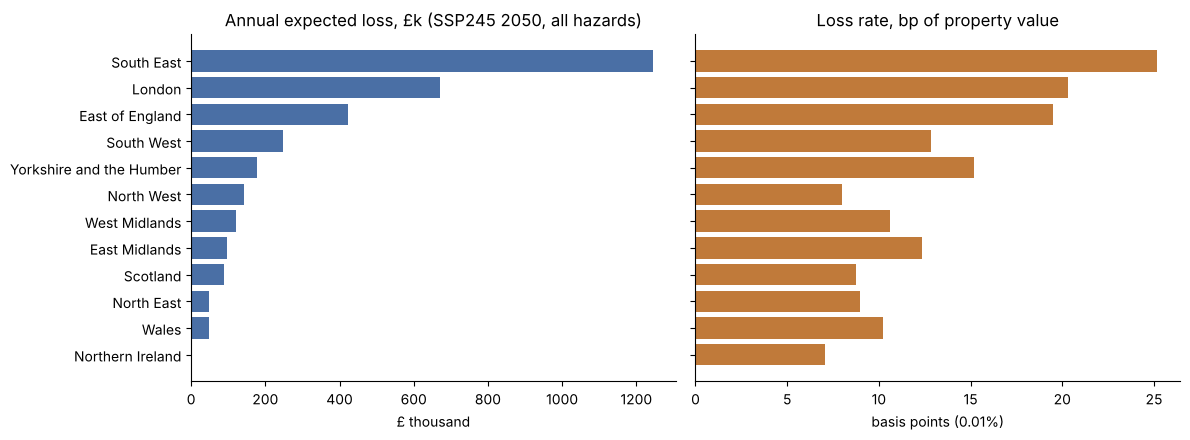

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
rr = reg.sort_values('loss_gbp')
ax[0].barh(rr.index, rr.loss_gbp/1e3, color='#4a6fa5'); ax[0].set_title('Annual expected loss, £k (SSP245 2050, all hazards)'); ax[0].set_xlabel('£ thousand')
ax[1].barh(rr.index, rr.loss_rate_bp, color='#c07a3a'); ax[1].set_title('Loss rate, bp of property value'); ax[1].set_xlabel('basis points (0.01%)'); ax[1].set_yticklabels([])
for a in ax: a.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.savefig('region_abs_vs_rate.png', dpi=120); plt.show()

**Observations (not priorities):**
- **One property dominates the loss:** P51627 (Retail, South East, £54.25m, one loan, L101623) is 12.77% of baseline loss and the largest balance (3.76% of £863.3m). Its subsidence is rated F
- **Mortgages vs CRE:** CRE is 243 of 1,880 properties but 72.99% of loss, because it holds 71.41% of property value. Per £ of value the two are close (17.54 vs 16.21bp), and stay close under every scenario. The absolute and normalised views tell different stories
- **Regions:** £ and rate ranks mostly agree. North West is 6th on £ but 11th on rate; Wales is 11th on £ but 8th on rate
- **Recent lending:** residential properties first lent on in 2021–25 have a higher loss rate (17.55bp) than 2010–15 (14.66bp). Property type and region mix by band is not controlled for
- **Subsidence** is 53.6% of baseline loss and the most scenario-sensitive hazard (SSP585 is 2.33× SSP245; flood 1.15×)

## 6. Limits: questions Sarah's audiences may ask that this file cannot answer
1. **"What does this cost the bank?"** (CRO, ICAAP) Needs LGD, insurance cover and default linkage; the file has property damage only
2. **"What changed since last quarter?"** (risk committee) One snapshot, no model version. Needs the previous quarterly files and Climate X's model version per delivery
3. **"Is this annual or cumulative, as of which valuation?"** (PRA, auditors) Needs Climate X's methodology notes
4. **"Which borrowers are most exposed?"** (credit committee) No borrower or counterparty ID, so exposure can't be grouped by obligor. Needs a borrower key from the loan system
5. **"How confident is the model?"** (PRA) No uncertainty ranges. Needs Climate X's confidence bands and validation

## 7. Product implications (requirements, solution-neutral)
- **State scenario, year, hazards, metric and counting basis with every number,** because each moves the total by the multiples in section 4
- **Apply one set of defaults across all audiences,** so the CRO pack, the PRA return and the pricing view reconcile
- **Count physical risk once per property** by default, and say so
- **Disclose missing scores** (number of loans, which hazard-year) and the denominator used
- **Label £ as damage to the property, not loss to the bank.** Caveat or decline "what will we lose" without bank-side assumptions
- **Show £ and loss rate together** where they rank segments differently
- **Keep an audit trail** (source file, delivery date, model version, assumptions) so any number can be defended to the PRA
- **Produce outputs in Excel and PowerPoint, in risk language,** because that's where Sarah and her audiences work
- **Normalise postcodes before any join,** and report records that don't match

## 8. Discovery questions
In `../discovery-questions.md`, built with the `discovery-interview` skill (15-minute budget) and published to Notion. Each data-informed question is tagged with the finding above that it comes from.